In [9]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [11]:
df = pd.read_csv("train(1).csv")

df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [12]:
df.shape

(200000, 202)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [14]:
df.isnull().sum()

ID_code    0
target     0
var_0      0
var_1      0
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64

In [15]:
df.head(10)

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104
5,train_5,0,11.4763,-2.3182,12.6080,8.6264,10.9621,3.5609,4.5322,15.2255,...,-6.3068,6.6025,5.2912,0.4403,14.9452,1.0314,-3.6241,9.7670,12.5809,-4.7602
6,train_6,0,11.8091,-0.0832,9.3494,4.2916,11.1355,-8.0198,6.1961,12.0771,...,8.7830,6.4521,3.5325,0.1777,18.3314,0.5845,9.1104,9.1143,10.8869,-3.2097
7,train_7,0,13.5580,-7.9881,13.8776,7.5985,8.6543,0.8310,5.6890,22.3262,...,13.1700,6.5491,3.9906,5.8061,23.1407,-0.3776,4.2178,9.4237,8.6624,3.4806
8,train_8,0,16.1071,2.4426,13.9307,5.6327,8.8014,6.1630,4.4514,10.1854,...,1.4298,14.7510,1.6395,1.4181,14.8370,-1.9940,-1.0733,8.1975,19.5114,4.8453
9,train_9,0,12.5088,1.9743,8.8960,5.4508,13.6043,-16.2859,6.0637,16.8410,...,0.5543,6.3160,1.0371,3.6885,14.8344,0.4467,14.1287,7.9133,16.2375,14.2514


In [16]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001
199999,train_199999,0,10.8762,-5.7105,12.1183,8.0328,11.5577,0.3488,5.2839,15.2058,...,8.9842,1.6893,0.1276,0.3766,15.2101,-2.4907,-2.2342,8.1857,12.1284,0.1385


In [17]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 200000
Columns: 202


In [18]:
df.columns

Index(['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4',
       'var_5', 'var_6', 'var_7',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=202)

In [19]:
df.dtypes.value_counts()

float64    200
object       1
int64        1
Name: count, dtype: int64

In [20]:
df.isnull().sum().sum()

np.int64(0)

In [21]:
df["target"].value_counts()

target
0    179902
1     20098
Name: count, dtype: int64

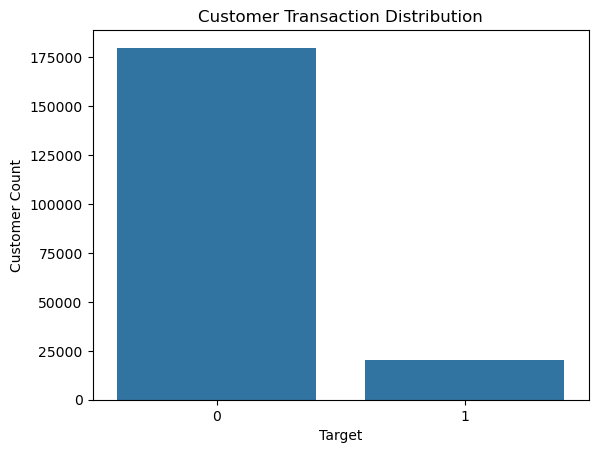

In [22]:
sns.countplot(x="target", data=df)

plt.title("Customer Transaction Distribution")
plt.xlabel("Target")
plt.ylabel("Customer Count")

plt.show()

In [23]:
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
X = df.drop(["ID_code", "target"], axis=1)

y = df["target"]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (200000, 200)
Output shape: (200000,)


In [26]:
print(X.isnull().sum().sum())

0


In [27]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [28]:
X.describe()

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,7.567236,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,1.235070,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,3.970500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,6.618800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,7.629600,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,8.584425,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,11.150600,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160000, 200)
Testing data: (40000, 200)


In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

Scaling completed!


In [31]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [32]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [33]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

print("ROC AUC:", roc_auc_score(
    y_test,
    model.predict_proba(X_test_scaled)[:, 1]
))

Accuracy: 0.9134
              precision    recall  f1-score   support

           0       0.92      0.99      0.95     35980
           1       0.68      0.26      0.38      4020

    accuracy                           0.91     40000
   macro avg       0.80      0.62      0.66     40000
weighted avg       0.90      0.91      0.90     40000

ROC AUC: 0.8598618773835104


In [34]:
# Random Forest

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [36]:
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained!")

Random Forest Model Trained!


In [37]:
rf_pred = rf_model.predict(X_test)

print(rf_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [38]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8995


In [39]:
from sklearn.metrics import roc_auc_score

rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.8011220094635216


In [40]:
lr_prob = model.predict_proba(X_test_scaled)[:, 1]

lr_auc = roc_auc_score(y_test, lr_prob)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        rf_accuracy
    ],
    "ROC_AUC": [
        lr_auc,
        rf_auc
    ]
})

comparison

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.9134,0.859862
1,Random Forest,0.8995,0.801122


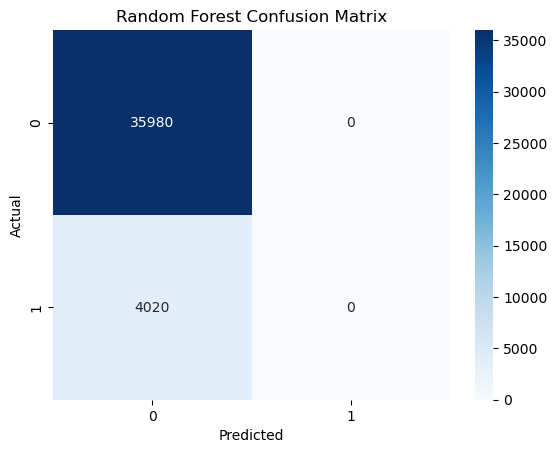

In [41]:
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [42]:
new_customer = X_test.iloc[[0]]

prediction = rf_model.predict(new_customer)

if prediction[0] == 1:
    print("Customer is likely to transact")
else:
    print("Customer is unlikely to transact")

Customer is unlikely to transact


In [43]:
# Model Improvement

In [44]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
81,var_81,0.042234
139,var_139,0.031739
12,var_12,0.028358
109,var_109,0.022584
53,var_53,0.021963
110,var_110,0.020955
26,var_26,0.019682
146,var_146,0.017971
174,var_174,0.017716
22,var_22,0.017498


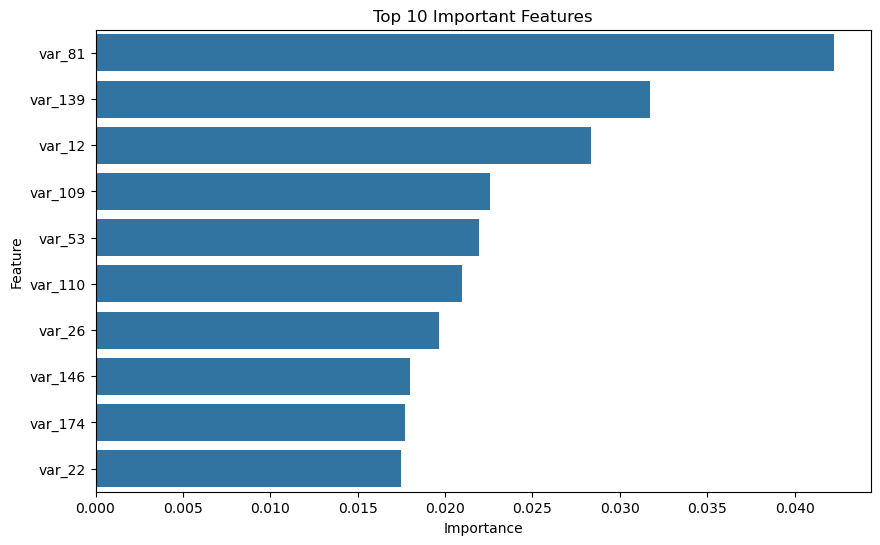

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.show()

In [47]:
from sklearn.metrics import accuracy_score, roc_auc_score

lr_accuracy = accuracy_score(y_test, y_pred)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Logistic Regression Accuracy:", lr_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Logistic Regression Accuracy: 0.9134
Random Forest Accuracy: 0.8995


In [48]:
lr_probability = model.predict_proba(X_test_scaled)[:, 1]

rf_probability = rf_model.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, lr_probability)

rf_auc = roc_auc_score(y_test, rf_probability)

print("Logistic Regression AUC:", lr_auc)
print("Random Forest AUC:", rf_auc)

Logistic Regression AUC: 0.8598618773835104
Random Forest AUC: 0.8011220094635216


In [49]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [lr_accuracy, rf_accuracy],
    "ROC_AUC": [lr_auc, rf_auc]
})

print(results)

                 Model  Accuracy   ROC_AUC
0  Logistic Regression    0.9134  0.859862
1        Random Forest    0.8995  0.801122


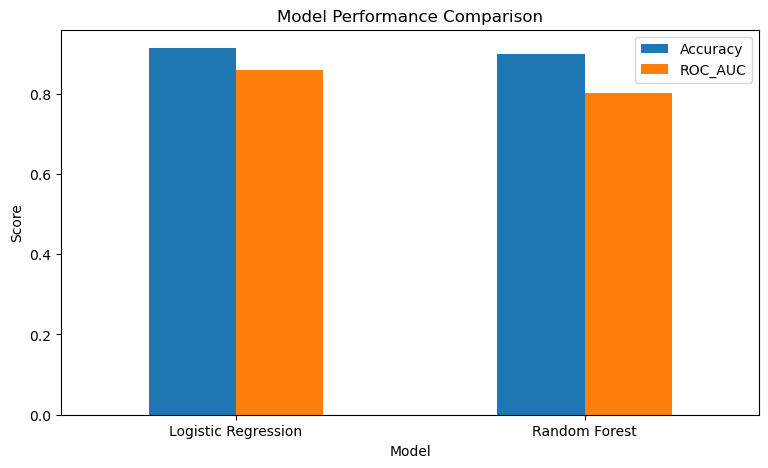

In [50]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

In [51]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance.head(10))

     Feature  Importance
81    var_81    0.042234
139  var_139    0.031739
12    var_12    0.028358
109  var_109    0.022584
53    var_53    0.021963
110  var_110    0.020955
26    var_26    0.019682
146  var_146    0.017971
174  var_174    0.017716
22    var_22    0.017498


In [52]:
# XGBoost Model

In [53]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   --- ------------------------------------ 4.7/48.9 MB 31.9 MB/s eta 0:00:02
   --------- ------------------------------ 11.5/48.9 MB 31.6 MB/s eta 0:00:02
   -------------- ------------------------- 17.8/48.9 MB 31.5 MB/s eta 0:00:01
   ------------------- -------------------- 24.4/48.9 MB 31.8 MB/s eta 0:00:01
   -------------------------- ------------- 33.0/48.9 MB 33.3 MB/s eta 0:00:01
   --------------------------------- ------ 41.2/48.9 MB 34.5 MB/s eta 0:00:01
   ---------------------------------------  48.5/48.9 MB 34.5 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 31.8 MB/s  0:00:01


In [54]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

In [55]:
xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [56]:
xgb_probability = xgb_model.predict_proba(X_test)[:, 1]

In [57]:
xgb_auc = roc_auc_score(
    y_test,
    xgb_probability
)

print("XGBoost ROC-AUC:", xgb_auc)

XGBoost ROC-AUC: 0.8653523274400647


In [58]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "ROC-AUC": [
        lr_auc,
        rf_auc,
        xgb_auc
    ]
})

print(final_results.sort_values(
    by="ROC-AUC",
    ascending=False
))

                 Model   ROC-AUC
2              XGBoost  0.865352
0  Logistic Regression  0.859862
1        Random Forest  0.801122


In [59]:
# Hyperparameter tuning

In [62]:
import gc

gc.collect()

print("Memory cleanup completed!")

Memory cleanup completed!


In [63]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [3, 4],
    "learning_rate": [0.03, 0.05],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

random_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        eval_metric="auc",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid,
    n_iter=3,
    scoring="roc_auc",
    cv=2,
    verbose=1,
    random_state=42,
    n_jobs=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best CV ROC-AUC:")
print(random_search.best_score_)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best Parameters:
{'subsample': 0.8, 'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV ROC-AUC:
0.8416670178800445


In [64]:
best_model = random_search.best_estimator_

import joblib

joblib.dump(
    best_model,
    "best_customer_transaction_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [65]:
best_probability = best_model.predict_proba(X_test)[:, 1]

best_auc = roc_auc_score(
    y_test,
    best_probability
)

print("Final ROC-AUC:", best_auc)

Final ROC-AUC: 0.8400414098213767


In [66]:
# check XGBoost tuning result

In [67]:
print("Best Parameters:")
print(random_search.best_params_)

print("Best CV ROC-AUC:")
print(random_search.best_score_)

Best Parameters:
{'subsample': 0.8, 'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV ROC-AUC:
0.8416670178800445


In [68]:
import joblib

best_model = random_search.best_estimator_

joblib.dump(
    best_model,
    "best_customer_transaction_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [69]:
best_probability = best_model.predict_proba(X_test)[:, 1]

best_auc = roc_auc_score(y_test, best_probability)

print("Final Test ROC-AUC:", best_auc)

Final Test ROC-AUC: 0.8400414098213767


In [70]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost Tuned"
    ],
    "ROC_AUC": [
        lr_auc,
        rf_auc,
        best_auc
    ]
})

print(final_comparison.sort_values(
    "ROC_AUC",
    ascending=False
))

                 Model   ROC_AUC
0  Logistic Regression  0.859862
2        XGBoost Tuned  0.840041
1        Random Forest  0.801122


In [71]:
import joblib

joblib.dump(
    xgb_model,
    "best_customer_transaction_model.pkl"
)

print("Original XGBoost model saved!")

Original XGBoost model saved!


In [72]:
from sklearn.metrics import classification_report

xgb_pred = xgb_model.predict(X_test)

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.91      1.00      0.95     35980
           1       0.88      0.08      0.15      4020

    accuracy                           0.91     40000
   macro avg       0.89      0.54      0.55     40000
weighted avg       0.90      0.91      0.87     40000



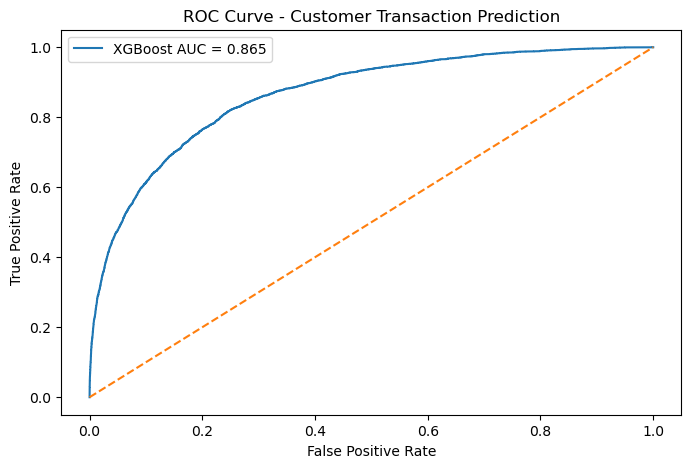

In [73]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    xgb_probability
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label="XGBoost AUC = %.3f" % xgb_auc
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Customer Transaction Prediction")

plt.legend()
plt.show()

In [74]:
!pip install streamlit

In [75]:
import joblib

joblib.dump(
    xgb_model,
    "best_customer_transaction_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
